# 01 — Momentum Factor Data Exploration

## Objective

Download, clean, validate, visualize, and save Kenneth French's official
**daily and monthly momentum factor returns**.

The official factor is a Fama–French-style momentum factor, not the stock-level
NYSE-decile P10–P1 portfolio reconstructed in Notebook 03.

**Data source:** [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html)

**Units:** French downloads are in percent; this notebook converts them to
decimal returns (e.g., 1.5% becomes 0.015).

**Outputs:**
- `data/processed/01_momentum_daily.parquet`
- `data/processed/01_momentum_monthly.parquet`

Notebook 02 reads these exact outputs. Both notebooks use the same cache-first Python loader; either can run first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from momentum_risk_project.data import load_momentum_returns

daily_clean, monthly_clean = load_momentum_returns()


Loaded cached daily data: /Users/guochuanchu/Downloads/momentum-risk-project/data/processed/01_momentum_daily.parquet
Loaded cached monthly data: /Users/guochuanchu/Downloads/momentum-risk-project/data/processed/01_momentum_monthly.parquet


## 1. Load daily momentum returns (cache-first)

The shared loader checks `data/processed/01_momentum_daily.parquet` first. If it is absent, the loader downloads the Kenneth French daily momentum factor, converts percentages to decimals, validates it, and saves the cache. The same rule applies independently to the monthly factor. Use `load_momentum_returns(force_download=True)` to refresh both datasets.

In [2]:
print('Daily rows:', len(daily_clean))
print('Daily date range:', daily_clean.index.min(), 'to', daily_clean.index.max())
print(daily_clean.head())

Daily rows: 16022
Daily date range: 1963-01-02 00:00:00 to 2026-08-31 00:00:00
               mom
date              
1963-01-02 -0.0053
1963-01-03 -0.0196
1963-01-04 -0.0066
1963-01-07 -0.0016
1963-01-08 -0.0043


In [3]:
daily_clean.head()

,mom
date,
1963-01-02,-0.0053
1963-01-03,-0.0196
1963-01-04,-0.0066
1963-01-07,-0.0016
1963-01-08,-0.0043


In [4]:
daily_df = daily_clean.copy()
print(daily_df.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 16022 entries, 1963-01-02 to 2026-08-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   mom     16022 non-null  float64
dtypes: float64(1)
memory usage: 250.3 KB
None


In [5]:
print("Rows:", len(daily_df))
print("Columns:", daily_df.columns.tolist())
print("Start date:", daily_df.index.min())
print("End date:", daily_df.index.max())

print("\nMissing values:")
print(daily_df.isna().sum())

print("\nDuplicate dates:")
print(daily_df.index.duplicated().sum())

Rows: 16022
Columns: ['mom']
Start date: 1963-01-02 00:00:00
End date: 2026-08-31 00:00:00

Missing values:
mom    0
dtype: int64

Duplicate dates:
0


## 2. Review cleaned daily data

The Python loader has already standardized the index, renamed `Mom` to `mom`, and converted percentage returns to decimal returns. Do not divide by 100 again.

In [6]:
print(daily_clean.head())
print(daily_clean.tail())
print('Missing daily returns:', daily_clean['mom'].isna().sum())

               mom
date              
1963-01-02 -0.0053
1963-01-03 -0.0196
1963-01-04 -0.0066
1963-01-07 -0.0016
1963-01-08 -0.0043
               mom
date              
2026-08-25 -0.0006
2026-08-26  0.0021
2026-08-27 -0.0023
2026-08-28 -0.0147
2026-08-31 -0.0014
Missing daily returns: 0


## 3. Validate daily data

Check dates, missing values, numeric validity, and conversion accuracy before using the series.

In [7]:
# Validate the daily index type
assert isinstance(daily_clean.index, pd.DatetimeIndex)

# Validate date uniqueness
assert daily_clean.index.is_unique

# Validate chronological ordering
assert daily_clean.index.is_monotonic_increasing

# Validate the return column
assert "mom" in daily_clean.columns

# Validate missing and non-finite values
assert daily_clean["mom"].notna().all()
assert np.isfinite(daily_clean["mom"].to_numpy()).all()

# Validate return bounds
assert (daily_clean["mom"] >= -1).all()

# Validate row count preservation
assert len(daily_clean) == len(daily_df)

print("All daily validation checks passed!")

All daily validation checks passed!


## 4. Explore daily returns

Examine dispersion, skewness, extreme daily observations, and tail behavior.

In [8]:
# Calculate descriptive statistics
print(daily_clean["mom"].describe())

# Identify extreme daily returns
print("\nMinimum daily return:")
print(daily_clean["mom"].idxmin(), daily_clean["mom"].min())

print("\nMaximum daily return:")
print(daily_clean["mom"].idxmax(), daily_clean["mom"].max())

# Calculate distribution characteristics
print("\nSkewness:")
print(daily_clean["mom"].skew())

print("\nExcess kurtosis:")
print(daily_clean["mom"].kurt())

count    16022.000000
mean         0.000283
std          0.007875
min         -0.143900
25%         -0.002500
50%          0.000600
75%          0.003600
max          0.071200
Name: mom, dtype: float64

Minimum daily return:
2020-11-09 00:00:00 -0.1439

Maximum daily return:
2009-04-20 00:00:00 0.0712

Skewness:
-1.2124031154620232

Excess kurtosis:
17.47605265285778


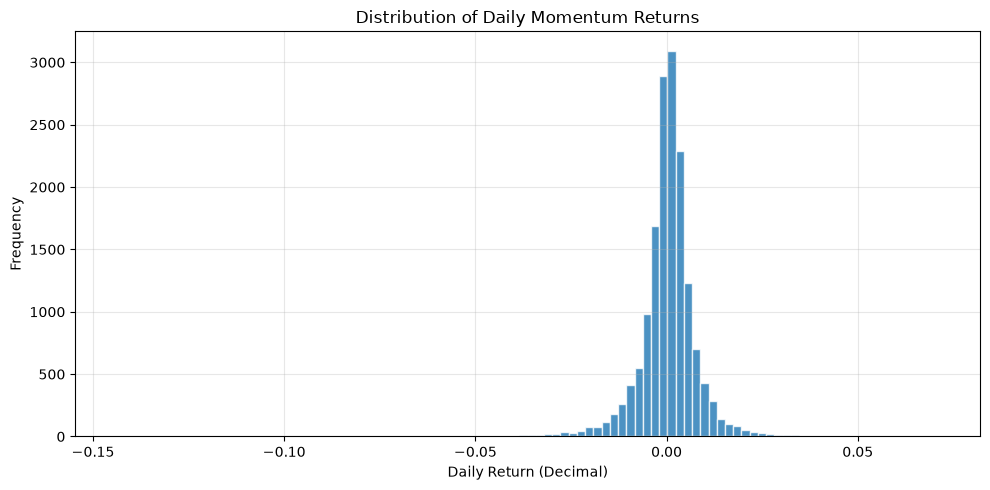

In [9]:
import matplotlib.pyplot as plt

# Plot the distribution of daily momentum returns
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    daily_clean["mom"],
    bins=100,
    edgecolor="white",
    alpha=0.8
)

ax.set_title("Distribution of Daily Momentum Returns")
ax.set_xlabel("Daily Return (Decimal)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

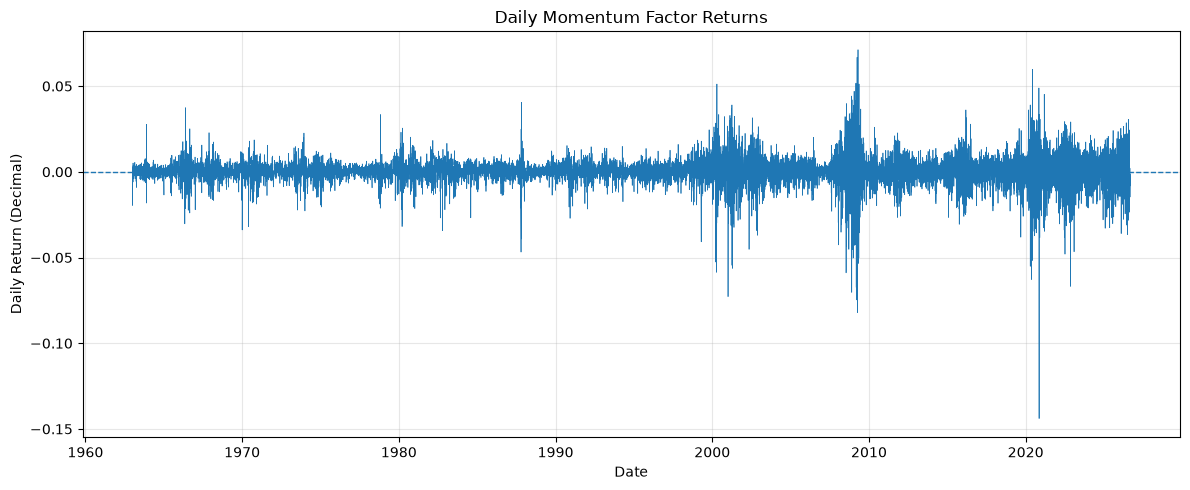

In [10]:
# Plot the daily momentum return time series
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    daily_clean.index,
    daily_clean["mom"],
    linewidth=0.5
)

ax.axhline(0, linestyle="--", linewidth=1)

ax.set_title("Daily Momentum Factor Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily Return (Decimal)")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Load monthly momentum returns (cache-first)

The shared loader independently checks `01_momentum_monthly.parquet` and downloads only when missing. The official monthly series is not assumed to equal compounded daily factor returns.

In [11]:
monthly_df = monthly_clean.copy()
print('Monthly date range:', monthly_clean.index.min(), 'to', monthly_clean.index.max())
print('Monthly rows:', len(monthly_clean))
print(monthly_clean.head())
print(monthly_clean.tail())

Monthly date range: 1963-01 to 2026-08
Monthly rows: 764
            mom
month          
1963-01 -0.0214
1963-02  0.0252
1963-03  0.0158
1963-04 -0.0006
1963-05  0.0029
            mom
month          
2026-04  0.0951
2026-05  0.0139
2026-06  0.0462
2026-07 -0.1220
2026-08 -0.0570


In [12]:
print('Monthly index type:', type(monthly_clean.index).__name__)
print('Missing monthly returns:', monthly_clean['mom'].isna().sum())

Monthly index type: PeriodIndex
Missing monthly returns: 0


## 6. Validate monthly data

Check monthly PeriodIndex frequency, chronological order, missing values, and percentage conversion.

In [13]:
# Validate the monthly index type
assert isinstance(monthly_clean.index, pd.PeriodIndex)

# Validate monthly frequency
assert monthly_clean.index.freqstr == "M"

# Validate date uniqueness
assert monthly_clean.index.is_unique

# Validate chronological ordering
assert monthly_clean.index.is_monotonic_increasing

# Validate missing and non-finite values
assert monthly_clean["mom"].notna().all()
assert np.isfinite(monthly_clean["mom"].to_numpy()).all()

# Validate row count preservation
assert len(monthly_clean) == len(monthly_df)

print("All monthly validation checks passed!")

All monthly validation checks passed!


## 7. Check monthly coverage

A complete monthly calendar helps identify missing observations before replication.

In [14]:
# Construct the expected monthly index
expected_months = pd.period_range(
    start=monthly_clean.index.min(),
    end=monthly_clean.index.max(),
    freq="M"
)

# Identify missing calendar months
missing_months = expected_months.difference(monthly_clean.index)

print("Expected months:", len(expected_months))
print("Actual months:", len(monthly_clean))
print("Missing months:", len(missing_months))
print(missing_months)

Expected months: 764
Actual months: 764
Missing months: 0
PeriodIndex([], dtype='period[M]')


## 8. Compare compounded daily and official monthly returns

The series may differ because of source construction and factor rebalancing conventions. Treat differences as a diagnostic, not an automatic data error.

In [15]:
# Assign each daily observation to its calendar month
daily_with_month = daily_clean.copy()
daily_with_month["month"] = daily_with_month.index.to_period("M")

# Compound daily returns within each month
daily_compounded = (
    daily_with_month
    .groupby("month")["mom"]
    .agg(lambda x: (1 + x).prod() - 1)
)

daily_compounded.name = "daily_compounded"

# Combine compounded daily returns with official monthly returns
comparison = pd.concat(
    [
        daily_compounded,
        monthly_clean["mom"].rename("official_monthly")
    ],
    axis=1,
    join="inner"
)

# Calculate the difference
comparison["difference"] = (
    comparison["daily_compounded"]
    - comparison["official_monthly"]
)

# Inspect the comparison
print(comparison.head(10))

print("\nComparison statistics:")
print(comparison["difference"].describe())

print("\nCorrelation:")
print(
    comparison["daily_compounded"].corr(
        comparison["official_monthly"]
    )
)

print("\nMean absolute difference:")
print(comparison["difference"].abs().mean())

         daily_compounded  official_monthly  difference
month                                                  
1963-01         -0.028600           -0.0214   -0.007200
1963-02          0.023837            0.0252   -0.001363
1963-03          0.020847            0.0158    0.005047
1963-04         -0.005392           -0.0006   -0.004792
1963-05          0.007898            0.0029    0.004998
1963-06          0.007064            0.0116   -0.004536
1963-07          0.013707            0.0101    0.003607
1963-08          0.005765            0.0100   -0.004235
1963-09         -0.003060            0.0012   -0.004260
1963-10          0.030431            0.0313   -0.000869

Comparison statistics:
count    764.000000
mean       0.000223
std        0.010047
min       -0.066313
25%       -0.004317
50%       -0.000118
75%        0.004675
max        0.075945
Name: difference, dtype: float64

Correlation:
0.9711318413758464

Mean absolute difference:
0.006734133895104762


## 9. Visualize monthly momentum returns

The first chart shows month-to-month returns; the second shows their distribution.
These plots complement the daily charts and make the frequency difference visible.

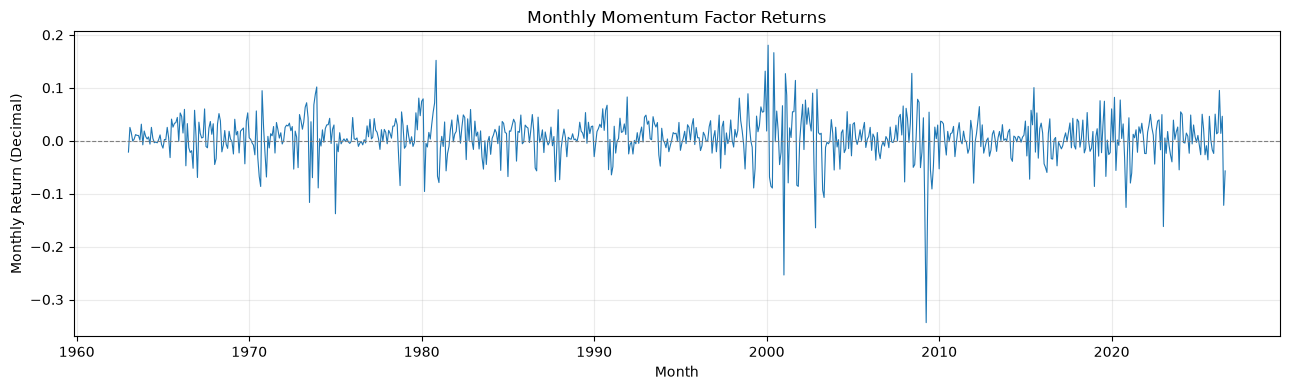

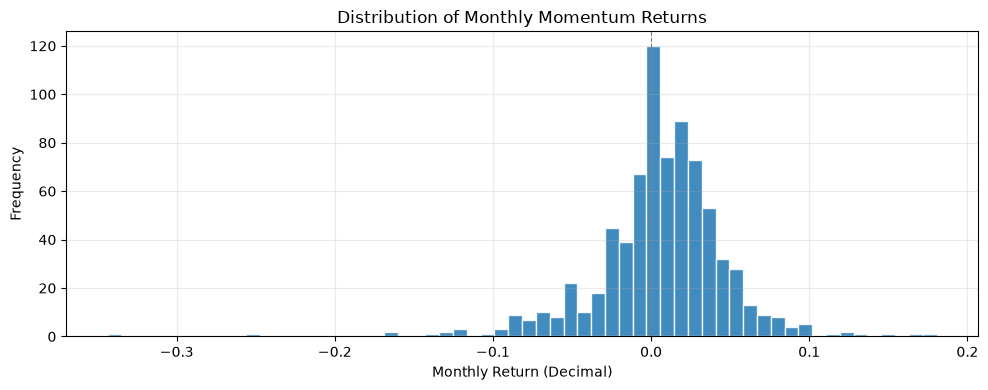

In [16]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(monthly_clean.index.to_timestamp(), monthly_clean["mom"], linewidth=0.8)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Monthly Momentum Factor Returns")
ax.set_xlabel("Month")
ax.set_ylabel("Monthly Return (Decimal)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(monthly_clean["mom"], bins=60, edgecolor="white", alpha=0.85)
ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Distribution of Monthly Momentum Returns")
ax.set_xlabel("Monthly Return (Decimal)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 10. Confirm cache files

The shared Python loader creates `01_momentum_daily.parquet` and `01_momentum_monthly.parquet` automatically on a cache miss. Verify the saved files without re-downloading or duplicating persistence logic.

In [17]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
DAILY_PATH = PROCESSED_DIR / '01_momentum_daily.parquet'
MONTHLY_PATH = PROCESSED_DIR / '01_momentum_monthly.parquet'

assert DAILY_PATH.is_file() and MONTHLY_PATH.is_file()
pd.testing.assert_frame_equal(daily_clean, pd.read_parquet(DAILY_PATH))
pd.testing.assert_frame_equal(monthly_clean, pd.read_parquet(MONTHLY_PATH))
print('Cache files exist and round-trip checks passed.')

Cache files exist and round-trip checks passed.
